# Complex geometric phase: ordered transport (multilayer) vs lateral arrays

Characterization of the v7b η-control meta-atom (c-Si two-fin on SiO₂, air above, u = junction position) against
**Jana & Genevet, "Complex Geometric Phase from Nonorthogonal Polarization Transport"** and its Supplemental Material (SM).

| Paper claim | Where it is tested |
|---|---|
| Eq. 9 / SM Eq. 22: cycle of $K(\phi,\eta)$ gives $\gamma_\pm=\pi\pm i\pi\eta/\sqrt{1-\eta^2}$ | §1 (analytic + discrete Wilson, SM Eq. 26–28) |
| SM Eq. 29–30: path reversal flips γ, dynamical phase unchanged | §1, §2, §4–§6 |
| Eq. 13–15 / SM Eq. 34–43: geometric propagator, $\mathcal A_{\rm circ}=2\eta/(1+\eta^2)$, SM §XI numbers | §1 |
| SM §XIII: a bilayer reproduces the asymmetry without transport | §1 |
| "A transverse array of unrelated matrices is not by itself a transport cycle" | §6 lateral PB supercells (full RCWA, all orders) |
| Ordered (longitudinal) transport realizes the holonomy | §4 ideal cascade, §5 full-RCWA multilayer stacks |

**Observable (SM §VIII, §XIII).** For a cycle $C$ and its reverse $C^{-1}$ through the *same* parameter values, the dynamical
factor $\prod_k\lambda_n(\theta_k)$ is identical, so the eigenbranch-resolved amplitude ratio
$|\langle L_n|M_C|R_n\rangle| / |\langle L_n|M_{C^{-1}}|R_n\rangle| = e^{-2\,\mathrm{Im}\,\gamma_n}$ isolates the geometric amplitude.
A lateral array's zero order is a sum over cells and cannot depend on their order (ratio 1 in the local-Jones model). A stack's
transmission is an ordered product.

**Physical rotation.** A PB rotation $R(\theta)=e^{-i\theta\sigma_y}$ (lab linear basis) rotates the $(\sigma_z,\sigma_x)$ components
and leaves $\sigma_y$ (circular) invariant. With $T=t_0I+\mathbf t\cdot\boldsymbol\sigma$ and $\hat k=\mathbf t/\sqrt{\mathbf t\cdot\mathbf t}$,
one rotation cycle gives $\gamma_\pm=\pi(1\mp\hat k_y)$ (`tests/test_theta_loop.py`). The paper's model realized by rotation is
$K'=\sigma_z+i\eta\sigma_y$ (non-Hermiticity along the rotation axis). A z-mirror-symmetric layer has $T=T^{\mathsf T}$, so
$\hat k_y=0$ and $\gamma=\pi$ exactly, whatever η.

In [1]:
from pathlib import Path
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.linalg import expm

from engine_twofin_eta import (Physics, RCWA, Modulation, design_from_raw, numpy_metrics, pauli_khat,
                               theta_loop_phase, transpose_asymmetry, virtual_wilson)
import engine_transport_test as X

OUT = Path('results/complex_pb_transport_test'); OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CKPT = Path('results/eta_control_v7b_twofin/complex_pb_checkpoint.npz')
PHYS = Physics(n_fin=3.88, k_fin=0.019, n_background=1.0, n_bottom=1.46, n_top=1.0, height=0.495)
MOD = Modulation(parameter='junction_frac', amplitude=0.10)
OPTS = RCWA(order=10, raster=192, device=DEVICE, precision='complex128')   # NV + area-fraction mask
raw = np.load(CKPT, allow_pickle=False)['raw']
GEOM = {k: float(v) for k, v in design_from_raw(torch.tensor(raw, dtype=torch.float64)).items()}
U_TEST = (-1.0, 1.0)                 # u=-1: eta ~ 0.69 ; u=+1: eta ~ 0.03 (control)
THETA_GRID = np.arange(0, 180, 7.5)  # 24-point library; stacks / supercells use sub-grids
sx = np.array([[0, 1], [1, 0]]); sy = np.array([[0, -1j], [1j, 0]]); sz = np.diag([1., -1.]); I2 = np.eye(2)
Rot = lambda th: np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
print('Design:', {k: round(v, 4) for k, v in GEOM.items()}); print(PHYS)

Design: {'length1': 0.1808, 'width1': 0.057, 'length2': 0.251, 'width2': 0.0564, 'bend_deg': 141.8032, 'junction_frac': -0.035}
Physics(wavelength=0.633, period=0.4, n_fin=3.88, k_fin=0.019, n_background=1.0, n_bottom=1.46, n_top=1.0, height=0.495, cell_margin=0.012)


## 1 · The paper's minimal model, verified number by number
$K(\phi,\eta)=\cos\phi\,\sigma_x+\sin\phi\,\sigma_y+i\eta\sigma_z$ (linear basis). Explicit eigenvectors (SM Eq. 12), reciprocal bras
(SM Eq. 16–18), connection (SM Eq. 20–21), discrete Wilson product (SM Eq. 26), geometric propagator (SM Eq. 34, 38), conversion
asymmetry (SM Eq. 42), the numbers of SM §XI and the bilayer of SM §XIII.

In [2]:
K = lambda phi, eta: np.cos(phi)*sx + np.sin(phi)*sy + 1j*eta*sz
def paper_V(phi, eta):
    chi = np.sqrt(1-eta**2)
    return np.array([[np.exp(-1j*phi), np.exp(-1j*phi)], [chi-1j*eta, -chi-1j*eta]])/np.sqrt(2)   # SM Eq. 12
checks = {}
for eta in (0.2, 0.5, 0.9):
    chi = np.sqrt(1-eta**2)
    V = paper_V(0.7, eta); Kp = K(0.7, eta)
    assert np.allclose(Kp@V, V@np.diag([chi, -chi]))                                   # SM Eq. 13
    s = np.vdot(V[:, 0], V[:, 1]); assert np.isclose(abs(s), eta) and np.isclose(s, eta*(eta-1j*chi))   # SM Eq. 14-15
    for N in (16, 128, 1024):                                                           # SM Eq. 26-28
        phis = 2*np.pi*np.arange(N+1)/N
        Vs = [paper_V(f, eta) for f in phis]
        W = np.prod([np.diag(np.linalg.inv(Vs[j])@Vs[j+1]) for j in range(N)], axis=0)
        g = 1j*np.log(W)
        checks[(eta, N)] = g
    g = checks[(eta, 1024)]; exact = np.pi*eta/chi
    g_ext = (8*checks[(eta, 1024)] - checks[(eta, 128)])/7          # Richardson: the discrete error is O(1/N)
    print(f"η={eta}: Wilson N=1024 γ± = {np.round(g, 4)} | N→∞ (Richardson) = {np.round(g_ext, 4)} | Eq. 22: π ± i{exact:.4f}")
    assert np.allclose(np.abs(g_ext.imag), exact, rtol=1e-3)
    # path reversal (SM Eq. 29)
    grev = {}
    for N in (128, 1024):
        Vs = [paper_V(f, eta) for f in (2*np.pi*np.arange(N+1)/N)[::-1]]
        grev[N] = 1j*np.log(np.prod([np.diag(np.linalg.inv(Vs[j])@Vs[j+1]) for j in range(N)], axis=0))
    grev_ext = (8*grev[1024] - grev[128])/7
    print(f"      reversed path C⁻¹ (Richardson): γ± = {np.round(grev_ext, 4)}  (SM Eq. 29: -γ)")
    assert np.allclose(grev_ext.imag, -g_ext.imag, rtol=1e-3)
print('SM Eq. 12-29 reproduced (eigenvectors, overlap, Wilson product, path reversal).')

# SM §IX-XI: geometric propagator, circular conversion, representative numbers
U = np.array([[1, 1], [-1j, 1j]])/np.sqrt(2)                                   # SM Eq. 36
for eta, ref in ((0.5, dict(im=1.8138, G=7.06e-4, C=9.54, A=0.800)), (0.9, dict(im=6.487, G=5.39e-12, C=25.58, A=0.9945))):
    chi = np.sqrt(1-eta**2); alpha = np.pi*eta/chi
    J = -expm(-(alpha/chi)*K(0, eta))                                           # SM Eq. 33
    assert np.allclose(J, -np.cosh(alpha)*I2 + np.sinh(alpha)/chi*K(0, eta))    # SM Eq. 34
    Jc = np.linalg.inv(U)@J@U
    assert np.allclose(Jc, [[-np.cosh(alpha), 1j*(1+eta)/chi*np.sinh(alpha)], [-1j*(1-eta)/chi*np.sinh(alpha), -np.cosh(alpha)]])  # SM Eq. 38
    A = X.conversion_asymmetry(J); G = np.exp(-4*np.pi*eta/chi); Cdb = 10*np.log10(abs(Jc[0, 1])**2/abs(Jc[1, 0])**2)
    print(f"η={eta}: Im γ+={alpha:.4f} (SM {ref['im']}), G+/G-={G:.3g} (SM {ref['G']}), C={Cdb:.2f} dB (SM {ref['C']}), A={A:.4f} (SM {ref['A']})")
    assert np.isclose(alpha, ref['im'], rtol=1e-3) and np.isclose(G, ref['G'], rtol=1e-2) and np.isclose(Cdb, ref['C'], atol=0.01) and np.isclose(A, ref['A'], atol=1e-4)
print('SM §IX-XI reproduced.')

# What Eq. 15 does and does not certify: any analytic function a I + b K(0,eta) has the same off-diagonal ratio.
for eta in (0.5, 0.9):
    thin = expm(-1j*0.05*K(0, eta))       # one thin element, no transport, no geometric amplitude
    print(f"η={eta}: single thin K(0,η) element A_circ = {X.conversion_asymmetry(thin):.4f}  vs  2η/(1+η²) = {2*eta/(1+eta**2):.4f}")

# SM §XIII bilayer (partial polarizer + quarter-wave element rotated together)
p_, q_ = 0.9, 0.3
D0 = np.diag([p_, q_]); Q4 = Rot(np.pi/4)@np.diag([np.exp(-1j*np.pi/4), np.exp(1j*np.pi/4)])@Rot(-np.pi/4)
Jtwo = Q4@D0
Jtc = np.linalg.inv(U)@Jtwo@U
print(f"SM §XIII bilayer: E(R<-L)={abs(Jtc[0,1])**2:.3f} (SM 0.405), E(L<-R)={abs(Jtc[1,0])**2:.3f} (SM 0.045), "
      f"A_two={X.conversion_asymmetry(Jtwo):.3f} (SM {(p_**2-q_**2)/(p_**2+q_**2):.3f})")
assert np.isclose(abs(Jtc[0, 1])**2, p_**2/2) and np.isclose(abs(Jtc[1, 0])**2, q_**2/2)
gt = theta_loop_phase(Jtwo)
print(f"   its rigid-rotation cycle (this work's γ = π(1∓k_y)): γ± = {np.round(gt, 4)}, ‖J-Jᵀ‖/‖J‖ = {transpose_asymmetry(Jtwo):.3f}")

η=0.2: Wilson N=1024 γ± = [-3.1416+0.6363j -3.1416-0.6463j] | N→∞ (Richardson) = [-3.1416+0.6413j -3.1416-0.6413j] | Eq. 22: π ± i0.6413
      reversed path C⁻¹ (Richardson): γ± = [-3.1416-0.6413j -3.1416+0.6413j]  (SM Eq. 29: -γ)
η=0.5: Wilson N=1024 γ± = [3.1416+1.8074j 3.1416-1.8202j] | N→∞ (Richardson) = [3.1416+1.8137j 3.1416-1.8137j] | Eq. 22: π ± i1.8138
      reversed path C⁻¹ (Richardson): γ± = [3.1416-1.8137j 3.1416+1.8137j]  (SM Eq. 29: -γ)
η=0.9: Wilson N=1024 γ± = [ 3.1416+6.4613j -3.1416-6.512j ] | N→∞ (Richardson) = [ 3.1416+6.4858j -3.1416-6.4857j] | Eq. 22: π ± i6.4866
      reversed path C⁻¹ (Richardson): γ± = [ 3.1416-6.4857j -3.1416+6.4858j]  (SM Eq. 29: -γ)
SM Eq. 12-29 reproduced (eigenvectors, overlap, Wilson product, path reversal).
η=0.5: Im γ+=1.8138 (SM 1.8138), G+/G-=0.000706 (SM 0.000706), C=9.54 dB (SM 9.54), A=0.8000 (SM 0.8)
η=0.9: Im γ+=6.4866 (SM 6.487), G+/G-=5.39e-12 (SM 5.39e-12), C=25.58 dB (SM 25.58), A=0.9945 (SM 0.9945)
SM §IX-XI reproduced.
η=0

## 2 · What physical rotation transports: ideal elements
Ideal thin layers, passive by a common loss κ ≥ η. Stack: ordered product over one rotation cycle (θ: 0→π, i.e. 2θ: 0→2π) for
both orientations. Lateral: the local-Jones zero order is the mean of the same matrices, independent of order.
* $K'(\eta)=\sigma_z+i\eta\sigma_y$: the paper's model realized by rotation (non-Hermiticity along the rotation axis).
* $K(0,\eta)=\sigma_x+i\eta\sigma_z$: the paper's $\phi=0$ generator, rotated physically (non-Hermiticity rotates with it; $T=T^{\mathsf T}$).

In [3]:
def ideal_stack(K0, N, Q, sense, kappa):
    M = I2.astype(complex); L = expm(-1j*K0*Q/N - kappa*Q/N*I2)
    for k in range(N):
        th = sense*np.pi*k/N; M = Rot(th)@L@Rot(-th)@M
    return M
ideal = {}
for name, K0 in (("K'=σz+iησy", sz + 1j*0.5*sy), ("K(0,η)=σx+iησz", sx + 1j*0.5*sz)):
    eta = 0.5; chi = np.sqrt(1-eta**2)
    T0 = expm(-1j*K0*0.01)
    print(f"{name}: one-cycle formula γ± = {np.round(theta_loop_phase(K0), 4)}")
    for N in (16, 64, 256):
        a = {s: X.eigenbranch_amplitudes(ideal_stack(K0, N, 20., s, 0.6), T0) for s in (+1, -1)}
        lat = {s: X.eigenbranch_amplitudes(np.mean([Rot(s*np.pi*k/N)@T0@Rot(-s*np.pi*k/N) for k in range(N)], axis=0), T0) for s in (+1, -1)}
        r = np.abs(a[+1])/np.abs(a[-1]); rl = np.abs(lat[+1])/np.abs(lat[-1])
        print(f"   N={N:4}: stack |a(+)|/|a(-)| = {np.round(r, 3)} | lateral (local) = {np.round(rl, 6)}")
        ideal[(name, N)] = dict(stack=r.tolist(), lateral=rl.tolist())
    print(f"   adiabatic prediction e^(±2 Im γ) = {np.exp(2*np.pi*eta/chi):.2f}, {np.exp(-2*np.pi*eta/chi):.4f}")

K'=σz+iησy: one-cycle formula γ± = [3.1416-1.8138j 3.1416+1.8138j]
   N=  16: stack |a(+)|/|a(-)| = [1.800e-02 5.631e+01] | lateral (local) = [1. 1.]
   N=  64: stack |a(+)|/|a(-)| = [2.500e-02 4.061e+01] | lateral (local) = [1. 1.]
   N= 256: stack |a(+)|/|a(-)| = [2.5000e-02 4.0092e+01] | lateral (local) = [1. 1.]
   adiabatic prediction e^(±2 Im γ) = 37.62, 0.0266
K(0,η)=σx+iησz: one-cycle formula γ± = [3.1416+0.j 3.1416+0.j]
   N=  16: stack |a(+)|/|a(-)| = [1. 1.] | lateral (local) = [1. 1.]
   N=  64: stack |a(+)|/|a(-)| = [1. 1.] | lateral (local) = [1. 1.]
   N= 256: stack |a(+)|/|a(-)| = [1. 1.] | lateral (local) = [1. 1.]
   adiabatic prediction e^(±2 Im γ) = 37.62, 0.0266


## 3 · The meta-atom library T(u, θ) and its rotation-cycle geometry
Uniform lattices of the v7b atom rotated by θ (NV, order 10, raster 192). For each u: η(θ), $\hat k_y(\theta)$ (rotation-invariant
for an ideal local atom), the one-solve formula, and the full lattice Wilson/transport product over θ with path reversal.

u=-1: η(θ=0)=0.671, ‖T-Tᵀ‖/‖T‖=0.063, formula γ± (θ=0) = [2.991+0.241j 3.292-0.241j]
   N= 6: transport γ (forward) = [-2.982+0.555j  2.89 +1.053j] | reversed = [ 2.89 +1.053j -2.982+0.555j]
   N=12: transport γ (forward) = [-3.019+0.149j  2.895+0.634j] | reversed = [ 2.895+0.634j -3.019+0.149j]
   N=24: transport γ (forward) = [-2.994-0.047j  2.931+0.434j] | reversed = [ 2.931+0.434j -2.994-0.047j]
   N→∞ (Richardson 12/24): Im γ = [-0.243  0.234]  vs one-solve formula ±0.241
u=+1: η(θ=0)=0.028, ‖T-Tᵀ‖/‖T‖=0.013, formula γ± (θ=0) = [3.12 -0.002j 3.163+0.002j]
   N= 6: transport γ (forward) = [-3.09 +0.871j  3.093+0.86j ] | reversed = [ 3.093+0.86j  -3.09 +0.871j]
   N=12: transport γ (forward) = [-3.094+0.422j  3.096+0.413j] | reversed = [ 3.096+0.413j -3.094+0.422j]
   N=24: transport γ (forward) = [-3.095+0.211j  3.096+0.202j] | reversed = [ 3.096+0.202j -3.095+0.211j]
   N→∞ (Richardson 12/24): Im γ = [ 0.001 -0.008]  vs one-solve formula ±0.002


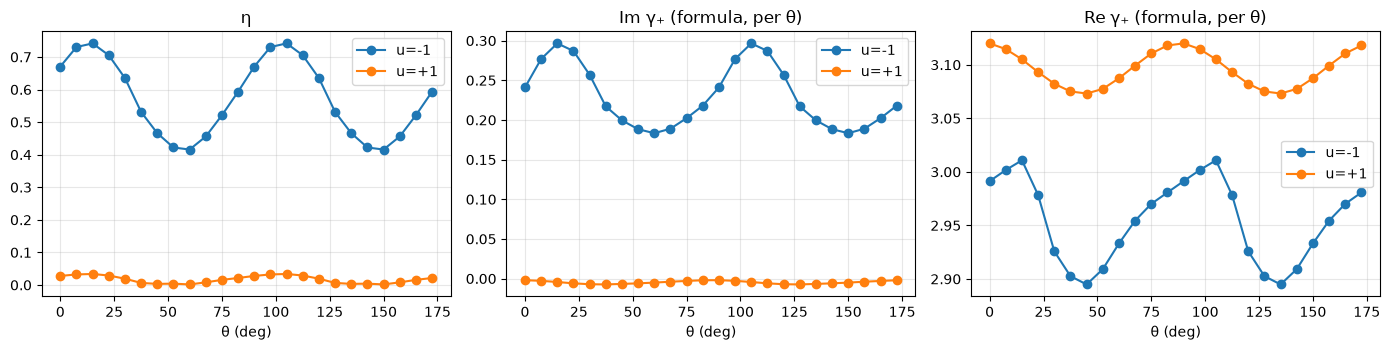

u=-1: single local element (no transport) circular-conversion asymmetry A = -0.924
u=+1: single local element (no transport) circular-conversion asymmetry A = -0.055


In [4]:
lib_file = OUT/'library.npz'
if lib_file.is_file():
    z = np.load(lib_file); LIB = {u: z[f'u{u:+.1f}'] for u in U_TEST}
else:
    LIB = {}
    for u in U_TEST:
        t0 = time.time(); LIB[u] = np.array([X.layer_T(GEOM, PHYS, OPTS, u, MOD, float(t))[0] for t in THETA_GRID])
        print(f'library u={u:+.1f}: {len(THETA_GRID)} solves, {time.time()-t0:.0f}s', flush=True)
    np.savez_compressed(lib_file, **{f'u{u:+.1f}': LIB[u] for u in U_TEST}, theta=THETA_GRID)
geo = {}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for u in U_TEST:
    Ts = LIB[u]; ky = np.array([pauli_khat(T)[1] for T in Ts]); eta = np.array([abs(np.vdot(X.eig_rl(T)[1][:, 0], X.eig_rl(T)[1][:, 1])) for T in Ts])
    axs[0].plot(THETA_GRID, eta, 'o-', label=f'u={u:+.0f}'); axs[1].plot(THETA_GRID, -np.pi*ky.imag, 'o-', label=f'u={u:+.0f}')
    axs[2].plot(THETA_GRID, np.pi*(1-ky.real), 'o-', label=f'u={u:+.0f}')
    rows = {}
    for step in (4, 2, 1):                       # N = 6, 12, 24 layers per cycle
        sub = list(Ts[::step]); fw = X.transport_prediction(sub); bw = X.transport_prediction(sub[:1]+sub[1:][::-1])
        rows[len(sub)] = dict(gamma_fw=fw['gamma'], gamma_bw=bw['gamma'], swap=fw['branch_swap'])
    form = theta_loop_phase(Ts[0])
    geo[u] = dict(rows=rows, formula=form, eta0=float(eta[0]), asym=transpose_asymmetry(Ts[0]))
    print(f"u={u:+.0f}: η(θ=0)={eta[0]:.3f}, ‖T-Tᵀ‖/‖T‖={geo[u]['asym']:.3f}, formula γ± (θ=0) = {np.round(form, 3)}")
    for n, r in rows.items():
        print(f"   N={n:2}: transport γ (forward) = {np.round(r['gamma_fw'], 3)} | reversed = {np.round(r['gamma_bw'], 3)}"
              f"{'  [branch swap]' if r['swap'] else ''}")
    gext = 2*rows[24]['gamma_fw'] - rows[12]['gamma_fw']      # discrete error is O(1/N), as in §1
    geo[u]['gamma_ext'] = gext
    print(f"   N→∞ (Richardson 12/24): Im γ = {np.round(gext.imag, 3)}  vs one-solve formula ±{abs(form[0].imag):.3f}")
for a, t in zip(axs, ('η', 'Im γ₊ (formula, per θ)', 'Re γ₊ (formula, per θ)')): a.set(xlabel='θ (deg)', title=t); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
for u in U_TEST:
    print(f"u={u:+.0f}: single local element (no transport) circular-conversion asymmetry A = {X.conversion_asymmetry(LIB[u][0]):+.3f}")

## 4 · Ideal cascade of meta-atom layers (Jones products, no interlayer reflection)
Exact ordered products of library matrices, $M_\pm=T(\theta_{N-1})\cdots T(\theta_0)$ with $\theta_k=\pm\pi k/N$, compared with the
adiabatic transport prediction $\prod\lambda_n\prod\langle L_n(k{+}1)|R_n(k)\rangle$. Only the dominant branch is reliable when
$|\lambda_2/\lambda_1|^N$ is small, because non-adiabatic leakage from the strong branch then swamps the weak one.

In [5]:
casc = {}
for u in U_TEST:
    Ts = LIB[u]
    for step in (4, 2, 1):
        sub = list(Ts[::step]); N = len(sub)
        Mf = np.eye(2, dtype=complex); Mb = np.eye(2, dtype=complex)
        for T in sub: Mf = T@Mf
        for T in sub[:1]+sub[1:][::-1]: Mb = T@Mb
        af, ab = X.eigenbranch_amplitudes(Mf, sub[0]), X.eigenbranch_amplitudes(Mb, sub[0])
        pf, pb = X.transport_prediction(sub), X.transport_prediction(sub[:1]+sub[1:][::-1])
        pred = np.abs(pf['geometric'])/np.abs(pb['geometric'])
        casc[(u, N)] = dict(ratio=(np.abs(af)/np.abs(ab)).tolist(), pred=pred.tolist(),
                            lam_ratio=float(abs(X.eig_rl(sub[0])[0][1]/X.eig_rl(sub[0])[0][0])))
        print(f"u={u:+.0f} N={N:2}: cascade |a(+)|/|a(-)| = {np.round(np.abs(af)/np.abs(ab), 3)} | adiabatic prediction = {np.round(pred, 3)}"
              f" | |λ2/λ1| = {casc[(u, N)]['lam_ratio']:.2f}")

u=-1 N= 6: cascade |a(+)|/|a(-)| = [2.208 1.276] | adiabatic prediction = [1.646 0.608] | |λ2/λ1| = 0.41
u=-1 N=12: cascade |a(+)|/|a(-)| = [1.686 1.405] | adiabatic prediction = [1.624 0.616] | |λ2/λ1| = 0.41
u=-1 N=24: cascade |a(+)|/|a(-)| = [1.628 1.46 ] | adiabatic prediction = [1.618 0.618] | |λ2/λ1| = 0.41
u=+1 N= 6: cascade |a(+)|/|a(-)| = [0.986 1.001] | adiabatic prediction = [0.99 1.01] | |λ2/λ1| = 0.80
u=+1 N=12: cascade |a(+)|/|a(-)| = [0.991 0.981] | adiabatic prediction = [0.991 1.009] | |λ2/λ1| = 0.80
u=+1 N=24: cascade |a(+)|/|a(-)| = [0.991 0.858] | adiabatic prediction = [0.991 1.009] | |λ2/λ1| = 0.80


## 5 · Full-RCWA multilayer stacks
N rotated copies of the layer in one RCWA solve: substrate | layer | air gap | SiO₂ spacer | layer | … | air. Every patterned layer keeps
its designed environment, which is what makes $T\neq T^{\mathsf T}$. Interlayer multiple reflections and near-field coupling are
included. Two spacer choices test Fabry-Pérot sensitivity.

In [6]:
stack = {}
SPACERS = ((0.25, 0.50), (0.40, 0.30))
for u in U_TEST:
    for N, step in ((6, 4), (12, 2)):
        thf = THETA_GRID[::step]; thb = np.concatenate((thf[:1], -thf[1:][::-1] % 180))
        T0 = LIB[u][0]
        for gap, spc in SPACERS:
            t0 = time.time()
            Mf, _ = X.stack_T(GEOM, PHYS, OPTS, u, MOD, thf, gap, spc)
            Mb, _ = X.stack_T(GEOM, PHYS, OPTS, u, MOD, -thf, gap, spc)   # same angles, reversed rotation sense
            af, ab = X.eigenbranch_amplitudes(Mf, T0), X.eigenbranch_amplitudes(Mb, T0)
            stack[(u, N, gap, spc)] = dict(ratio=(np.abs(af)/np.abs(ab)).tolist(), a_f=af.tolist(), a_b=ab.tolist(),
                                           P=float(np.sum(abs(Mf)**2)/2), A_f=X.conversion_asymmetry(Mf), A_b=X.conversion_asymmetry(Mb))
            print(f"u={u:+.0f} N={N:2} gap {gap} / SiO2 {spc} µm: |a(+)|/|a(-)| = {np.round(np.abs(af)/np.abs(ab), 3)} | "
                  f"cascade {np.round(casc[(u, N)]['ratio'], 3)} | mean T = {stack[(u, N, gap, spc)]['P']:.2e} | "
                  f"A_circ(+,-) = {stack[(u, N, gap, spc)]['A_f']:+.3f}, {stack[(u, N, gap, spc)]['A_b']:+.3f} | {time.time()-t0:.0f}s", flush=True)

u=-1 N= 6 gap 0.25 / SiO2 0.5 µm: |a(+)|/|a(-)| = [1.274 0.331] | cascade [2.208 1.276] | mean T = 5.08e-02 | A_circ(+,-) = -0.778, -0.856 | 145s


u=-1 N= 6 gap 0.4 / SiO2 0.3 µm: |a(+)|/|a(-)| = [2.057 1.928] | cascade [2.208 1.276] | mean T = 4.10e-02 | A_circ(+,-) = -0.556, -0.825 | 141s


u=-1 N=12 gap 0.25 / SiO2 0.5 µm: |a(+)|/|a(-)| = [1.082 0.478] | cascade [1.686 1.405] | mean T = 1.89e-04 | A_circ(+,-) = -0.812, -0.898 | 408s


u=-1 N=12 gap 0.4 / SiO2 0.3 µm: |a(+)|/|a(-)| = [1.563 3.923] | cascade [1.686 1.405] | mean T = 1.75e-02 | A_circ(+,-) = -0.692, -0.814 | 385s


u=+1 N= 6 gap 0.25 / SiO2 0.5 µm: |a(+)|/|a(-)| = [0.947 0.886] | cascade [0.986 1.001] | mean T = 5.82e-02 | A_circ(+,-) = -0.024, -0.035 | 137s


u=+1 N= 6 gap 0.4 / SiO2 0.3 µm: |a(+)|/|a(-)| = [0.947 1.135] | cascade [0.986 1.001] | mean T = 7.24e-02 | A_circ(+,-) = -0.109, -0.086 | 137s


u=+1 N=12 gap 0.25 / SiO2 0.5 µm: |a(+)|/|a(-)| = [0.879 0.992] | cascade [0.991 0.981] | mean T = 1.85e-03 | A_circ(+,-) = -0.036, -0.010 | 377s


u=+1 N=12 gap 0.4 / SiO2 0.3 µm: |a(+)|/|a(-)| = [1.061 1.676] | cascade [0.991 0.981] | mean T = 4.74e-02 | A_circ(+,-) = -0.143, +0.014 | 377s


## 6 · Lateral PB supercells (full RCWA, all diffraction orders)
A 1×N supercell (cells along x) holds the same N rotations as the stack, side by side: a PB grating whose $\pm1$ orders carry the
$e^{\pm2i\theta}$ conversion. Reversing the rotation sense reverses the order of the cells. Local-Jones prediction: zero order = mean of the
cell matrices (order-independent, ratio 1); order $m$ = discrete Fourier component of the cell matrices. Any deviation of the
zero-order eigenbranch ratio from 1 measures lateral coupling, the only route by which an array could impart ordered transport.

In [7]:
lateral = {}
N = 6; thf = THETA_GRID[::4]
for u in U_TEST:
    T0 = LIB[u][0]; cells = LIB[u][::4]
    for oxy in ((6*N, 6), (8*N, 6)):
        t0 = time.time(); res = {}
        for s in (+1, -1):
            th = s*thf % 180
            res[s] = X.supercell_T(GEOM, PHYS, OPTS, u, MOD, th, oxy, orders=((0, 0), (1, 0), (-1, 0)))
        a = {s: X.eigenbranch_amplitudes(res[s][(0, 0)][2:4, :2], T0) for s in (+1, -1)}
        loc0 = np.mean(cells, axis=0); aloc = X.eigenbranch_amplitudes(loc0, T0)
        m1 = {s: {m: X.circular(res[s][(m, 0)][2:4, :2]) for m in (1, -1)} for s in (+1, -1)}
        floc = {m: X.circular(np.mean([c*np.exp(-2j*np.pi*m*j/N) for j, c in enumerate(cells)], axis=0)) for m in (1, -1)}
        lateral[(u, oxy)] = dict(ratio=(np.abs(a[+1])/np.abs(a[-1])).tolist(), a_plus=a[+1].tolist(), a_local=aloc.tolist(),
                                 eff={f'{s:+d}_{m:+d}': (abs(m1[s][m][0, 1])**2, abs(m1[s][m][1, 0])**2) for s in (+1, -1) for m in (1, -1)},
                                 eff_local={f'{m:+d}': (abs(floc[m][0, 1])**2, abs(floc[m][1, 0])**2) for m in (1, -1)})
        print(f"u={u:+.0f} orders {oxy}: zero-order |a(+)|/|a(-)| = {np.round(np.abs(a[+1])/np.abs(a[-1]), 4)} | "
              f"|a(+)| = {np.round(np.abs(a[+1]), 4)} vs local mean {np.round(np.abs(aloc), 4)} | {time.time()-t0:.0f}s", flush=True)
        for s in (+1, -1):
            print('     sense %+d: ' % s + ', '.join(f"order {m:+d} R←L {abs(m1[s][m][0,1])**2:.4f} / L←R {abs(m1[s][m][1,0])**2:.4f}" for m in (1, -1)))
        print('     local Jones: ' + ', '.join(f"order {m:+d} R←L {abs(floc[m][0,1])**2:.4f} / L←R {abs(floc[m][1,0])**2:.4f}" for m in (1, -1)))

u=-1 orders (36, 6): zero-order |a(+)|/|a(-)| = [0.8433 0.9252] | |a(+)| = [0.4025 0.4234] vs local mean [0.4855 0.4867] | 65s


     sense +1: order +1 R←L 0.0020 / L←R 0.0084, order -1 R←L 0.0037 / L←R 0.1631
     sense -1: order +1 R←L 0.0018 / L←R 0.1116, order -1 R←L 0.0487 / L←R 0.0002
     local Jones: order +1 R←L 0.0142 / L←R 0.0012, order -1 R←L 0.0015 / L←R 0.1909


u=-1 orders (48, 6): zero-order |a(+)|/|a(-)| = [0.8472 0.9207] | |a(+)| = [0.4109 0.4188] vs local mean [0.4855 0.4867] | 137s


     sense +1: order +1 R←L 0.0022 / L←R 0.0080, order -1 R←L 0.0030 / L←R 0.1601
     sense -1: order +1 R←L 0.0020 / L←R 0.1072, order -1 R←L 0.0457 / L←R 0.0002
     local Jones: order +1 R←L 0.0142 / L←R 0.0012, order -1 R←L 0.0015 / L←R 0.1909


u=+1 orders (36, 6): zero-order |a(+)|/|a(-)| = [0.7143 1.1759] | |a(+)| = [0.1977 0.2554] vs local mean [0.2194 0.2193] | 66s


     sense +1: order +1 R←L 0.2278 / L←R 0.0007, order -1 R←L 0.0028 / L←R 0.3121
     sense -1: order +1 R←L 0.0014 / L←R 0.2852, order -1 R←L 0.3323 / L←R 0.0007
     local Jones: order +1 R←L 0.4002 / L←R 0.0006, order -1 R←L 0.0009 / L←R 0.4267


u=+1 orders (48, 6): zero-order |a(+)|/|a(-)| = [0.7084 1.182 ] | |a(+)| = [0.1936 0.2407] vs local mean [0.2194 0.2193] | 108s


     sense +1: order +1 R←L 0.2247 / L←R 0.0007, order -1 R←L 0.0028 / L←R 0.3112
     sense -1: order +1 R←L 0.0013 / L←R 0.2857, order -1 R←L 0.3326 / L←R 0.0006
     local Jones: order +1 R←L 0.4002 / L←R 0.0006, order -1 R←L 0.0009 / L←R 0.4267


## 7 · Summary: does each arrangement impart the complex geometric amplitude?

In [8]:
print('Eigenbranch amplitude ratio |a(C)|/|a(C⁻¹)| for the dominant branch (geometric amplitude e^{∓2 Im γ}; 1 = none):')
for u in U_TEST:
    print(f"\nu={u:+.0f}  (η={geo[u]['eta0']:.2f}, ‖T-Tᵀ‖/‖T‖={geo[u]['asym']:.3f}, one-cycle formula Im γ± = ±{abs(geo[u]['formula'][0].imag):.3f})")
    print(f"   adiabatic prediction (N=12): {casc[(u, 12)]['pred'][0]:.3f}")
    print(f"   ideal Jones cascade (N=12):  {casc[(u, 12)]['ratio'][0]:.3f}")
    for gap, spc in SPACERS: print(f"   full-RCWA stack N=12, gap {gap}/SiO2 {spc}: {stack[(u, 12, gap, spc)]['ratio'][0]:.3f}")
    for oxy in ((36, 6), (48, 6)): print(f"   lateral supercell N=6, orders {oxy}: {lateral[(u, oxy)]['ratio'][0]:.4f}")
json.dump(dict(geo={str(u): dict(formula=[str(x) for x in g['formula']], eta0=g['eta0'], asym=g['asym'],
                                 rows={str(n): {k: (str(v) if k != 'swap' else v) for k, v in r.items()} for n, r in g['rows'].items()})
                    for u, g in geo.items()},
               cascade={f'{k}': v for k, v in casc.items()}, stack={f'{k}': {kk: (str(vv) if isinstance(vv, list) else vv) for kk, vv in v.items()} for k, v in stack.items()},
               lateral={f'{k}': {kk: (str(vv) if isinstance(vv, list) else vv) for kk, vv in v.items()} for k, v in lateral.items()},
               ideal={f'{k}': v for k, v in ideal.items()}), open(OUT/'transport_test_summary.json', 'w'), indent=1, default=str)
print('\nSaved', OUT/'transport_test_summary.json')

Eigenbranch amplitude ratio |a(C)|/|a(C⁻¹)| for the dominant branch (geometric amplitude e^{∓2 Im γ}; 1 = none):

u=-1  (η=0.67, ‖T-Tᵀ‖/‖T‖=0.063, one-cycle formula Im γ± = ±0.241)
   adiabatic prediction (N=12): 1.624
   ideal Jones cascade (N=12):  1.686
   full-RCWA stack N=12, gap 0.25/SiO2 0.5: 1.082
   full-RCWA stack N=12, gap 0.4/SiO2 0.3: 1.563
   lateral supercell N=6, orders (36, 6): 0.8433
   lateral supercell N=6, orders (48, 6): 0.8472

u=+1  (η=0.03, ‖T-Tᵀ‖/‖T‖=0.013, one-cycle formula Im γ± = ±0.002)
   adiabatic prediction (N=12): 0.991
   ideal Jones cascade (N=12):  0.991
   full-RCWA stack N=12, gap 0.25/SiO2 0.5: 0.879
   full-RCWA stack N=12, gap 0.4/SiO2 0.3: 1.061
   lateral supercell N=6, orders (36, 6): 0.7143
   lateral supercell N=6, orders (48, 6): 0.7084

Saved results/complex_pb_transport_test/transport_test_summary.json


## 8 · Separating geometric transport from full-wave artifacts
§5–§6 show two order-dependent effects that are *not* geometric: Fabry-Pérot interference between strongly reflecting layers (the
u=+1 control moves by ±12 %), and near-field coupling between neighbours with very different rotations in a steep lateral gradient.
* **8a.** Stacks with random spacer thicknesses (8 realizations, N=12, order 8). Averaging over Fabry-Pérot phases mimics a thick-spacer or
  broadband measurement. The geometric signal is the shift of $\ln(|a(C)|/|a(C^{-1})|)$ for u=−1 relative to the u=+1 control
  (prediction $2\,\mathrm{Im}\,\gamma\approx0.48$).
* **8b.** Lateral supercells with a gentler gradient (12 cells, 15° per cell). If the lateral zero-order ratio is coupling rather than
  transport, it should move toward 1 as the gradient becomes more adiabatic, for the control as much as for u=−1.

u=-1 gap 0.27 / SiO2 0.58: ln ratio (dominant) = +0.136 | 61s


u=-1 gap 0.39 / SiO2 0.42: ln ratio (dominant) = +0.135 | 61s


u=-1 gap 0.34 / SiO2 0.67: ln ratio (dominant) = +1.128 | 61s


u=-1 gap 0.56 / SiO2 0.31: ln ratio (dominant) = -0.131 | 61s


u=-1 gap 0.46 / SiO2 0.38: ln ratio (dominant) = -1.285 | 61s


...

u=+1 gap 0.46 / SiO2 0.38: ln ratio (dominant) = -0.046 | 62s


u=+1 gap 0.59 / SiO2 0.75: ln ratio (dominant) = +0.018 | 62s


u=+1 gap 0.45 / SiO2 0.65: ln ratio (dominant) = +0.039 | 62s


u=+1 gap 0.41 / SiO2 0.70: ln ratio (dominant) = +0.062 | 62s



median ln ratio: u=-1 +0.178 (IQR +0.069..+0.272), u=+1 +0.004 (IQR -0.046..+0.032)
geometric signal (u=-1 minus control) = +0.174  vs  prediction 2 Im γ = 0.485


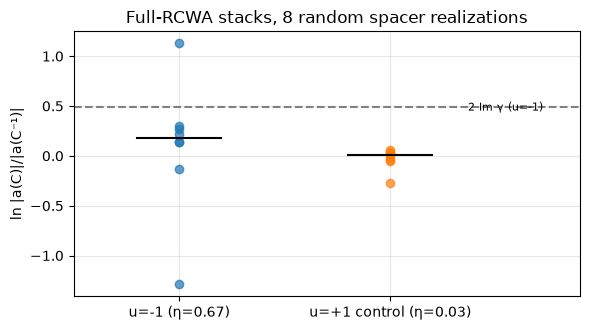

In [9]:
rng = np.random.default_rng(2026)
OPTS8 = RCWA(order=8, raster=160, device=DEVICE, precision='complex128')
REAL = [(float(rng.uniform(0.2, 0.6)), float(rng.uniform(0.2, 0.8))) for _ in range(8)]
thf = THETA_GRID[::2]
avg = {u: [] for u in U_TEST}
for u in U_TEST:
    T0 = X.layer_T(GEOM, PHYS, OPTS8, u, MOD, 0.)[0]
    for gap, spc in REAL:
        t0 = time.time()
        Mf, _ = X.stack_T(GEOM, PHYS, OPTS8, u, MOD, thf, gap, spc)
        Mb, _ = X.stack_T(GEOM, PHYS, OPTS8, u, MOD, -thf, gap, spc)
        r = np.abs(X.eigenbranch_amplitudes(Mf, T0))/np.abs(X.eigenbranch_amplitudes(Mb, T0))
        avg[u].append(float(np.log(r[0])))
        print(f"u={u:+.0f} gap {gap:.2f} / SiO2 {spc:.2f}: ln ratio (dominant) = {np.log(r[0]):+.3f} | {time.time()-t0:.0f}s", flush=True)
shift = np.median(avg[-1.0]) - np.median(avg[1.0])
spread = {u: (np.percentile(v, 25), np.percentile(v, 75)) for u, v in avg.items()}
pred = 2*abs(geo[-1.0]['gamma_ext'][0].imag)
print(f"\nmedian ln ratio: u=-1 {np.median(avg[-1.0]):+.3f} (IQR {spread[-1.0][0]:+.3f}..{spread[-1.0][1]:+.3f}), "
      f"u=+1 {np.median(avg[1.0]):+.3f} (IQR {spread[1.0][0]:+.3f}..{spread[1.0][1]:+.3f})")
print(f"geometric signal (u=-1 minus control) = {shift:+.3f}  vs  prediction 2 Im γ = {pred:.3f}")
fig, ax = plt.subplots(figsize=(6, 3.4))
for i, u in enumerate(U_TEST):
    ax.plot([i]*len(avg[u]), avg[u], 'o', alpha=.7); ax.plot([i-.2, i+.2], [np.median(avg[u])]*2, 'k-')
ax.axhline(pred, ls='--', color='gray'); ax.text(1.35, pred, ' 2 Im γ (u=-1)', va='center', fontsize=8)
ax.set(xticks=[0, 1], xticklabels=['u=-1 (η=0.67)', 'u=+1 control (η=0.03)'], ylabel='ln |a(C)|/|a(C⁻¹)|', xlim=(-.5, 1.9),
       title='Full-RCWA stacks, 8 random spacer realizations'); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

In [10]:
lateral12 = {}
N12 = 12; th12 = THETA_GRID[::2]
for u in U_TEST:
    T0 = LIB[u][0]; t0 = time.time(); res = {}
    for s_ in (+1, -1):
        res[s_] = X.supercell_T(GEOM, PHYS, OPTS8, u, MOD, s_*th12 % 180, (6*N12, 6), orders=((0, 0),))
    a = {s_: X.eigenbranch_amplitudes(res[s_][(0, 0)][2:4, :2], T0) for s_ in (+1, -1)}
    aloc = X.eigenbranch_amplitudes(np.mean(LIB[u][::2], axis=0), T0)
    lateral12[u] = (np.abs(a[+1])/np.abs(a[-1])).tolist()
    print(f"u={u:+.0f} 12 cells (15°/cell): zero-order |a(+)|/|a(-)| = {np.round(lateral12[u], 4)} | |a(+)| = {np.round(np.abs(a[+1]), 4)} "
          f"vs local mean {np.round(np.abs(aloc), 4)} | {time.time()-t0:.0f}s", flush=True)
print('\nLateral zero-order ratio (dominant branch), 6 cells (30°/cell) vs 12 cells (15°/cell):')
for u in U_TEST: print(f"   u={u:+.0f}: {lateral[(u, (48, 6))]['ratio'][0]:.3f} -> {lateral12[u][0]:.3f}")
json.dump(dict(stack_ln_ratio={str(u): v for u, v in avg.items()}, realizations=REAL, geometric_shift=float(shift), prediction=float(pred),
               lateral12={str(u): v for u, v in lateral12.items()}), open(OUT/'transport_test_followup.json', 'w'), indent=1)

u=-1 12 cells (15°/cell): zero-order |a(+)|/|a(-)| = [0.9285 1.0461] | |a(+)| = [0.4323 0.4851] vs local mean [0.4856 0.4868] | 227s


u=+1 12 cells (15°/cell): zero-order |a(+)|/|a(-)| = [0.7549 1.0084] | |a(+)| = [0.2127 0.2425] vs local mean [0.2193 0.2192] | 225s



Lateral zero-order ratio (dominant branch), 6 cells (30°/cell) vs 12 cells (15°/cell):
   u=-1: 0.847 -> 0.929
   u=+1: 0.708 -> 0.755
